# Tumor classification: confusion matrix, error metrics, ROC and precision-recall (FIXED)

**Convention used everywhere below:** `y = 1` means **malignant** (the *positive* class), `y = 0` means **benign**.

Bugs fixed compared with the original `tumor.ipynb` are marked with `# FIX`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

data = load_breast_cancer()
print("sklearn target_names:", data.target_names, "-> in sklearn, 0 = malignant, 1 = benign")

x = pd.DataFrame(data.data, columns=data.feature_names)

# We FLIP the sklearn target so that malignant = 1 (positive class)
y = pd.Series((data.target == 0).astype(int), name="malignant")
# print(data.target)
print(y.value_counts())
print("Feature matrix shape:", x.shape)
print("Target shape:", y.shape)

sklearn target_names: ['malignant' 'benign'] -> in sklearn, 0 = malignant, 1 = benign
malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape: (569, 30)
Target shape: (569,)


## 1. Class distribution

**FIX:** the original code paired `data.target_names` (`['malignant','benign']`) with counts sorted by the *flipped* label (`0 = benign`, `1 = malignant`). That printed the benign count (357) next to the word "malignant". The names must follow the labels we actually created.

In [ ]:
label_names = {0: "benign", 1: "malignant"}          # FIX: names follow OUR labels
class_counts = y.value_counts()          # index 0 (benign), then 1 (malignant)
class_distribution = pd.DataFrame({
    "Class": [label_names[i] for i in class_counts.index],
    "Count": class_counts.values,
    "Probability": class_counts.values / len(y)
})
print(class_distribution)

malignant
0    357
1    212
Name: count, dtype: int64
       Class  Count  Probability
0     benign    357     0.627417
1  malignant    212     0.372583


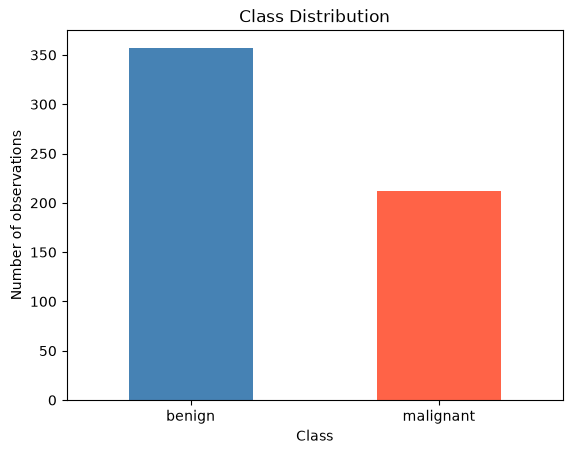

In [6]:
class_distribution.plot(
    x="Class", y="Count", kind="bar", legend=False,
    color=["steelblue", "tomato"]                     # benign = blue, malignant = red (same order as the table)
)
plt.ylabel("Number of observations")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

## 2. Stratified train / test split and model

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training size:", len(y_train))
print("Testing size:", len(y_test))
print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training size: 455
Testing size: 114

Training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Testing proportions:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [8]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
model.fit(X_train, y_train)
print("Class order inside the model (column order of predict_proba):", model.classes_)

Class order inside the model (column order of predict_proba): [0 1]


## 3. Predicted probabilities

`predict_proba` returns one column **per class, in the order of `model.classes_`**. Here that order is `[0, 1]`, so

* column 0 = P(benign)
* column 1 = P(malignant)

**FIX:** the original code used `probabilities[:, 0]` as `P_malignant`. That is actually P(benign), so every threshold result downstream was inverted. We look the column up by class label so it can never be mixed up.

In [10]:
probabilities = model.predict_proba(X_test)
mal_col = list(model.classes_).index(1)      # FIX: column that belongs to class 1 = malignant
ben_col = list(model.classes_).index(0)

p_malignant = probabilities[:, mal_col]
p_benign = probabilities[:, ben_col]

print(probabilities[:5])
print("\nRow sums (must all be 1):", probabilities[:5].sum(axis=1))

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]

Row sums (must all be 1): [1. 1. 1. 1. 1.]


In [11]:
results = pd.DataFrame({
    "Actual_class": y_test.values,
    "P_malignant": p_malignant,       # FIX
    "P_benign": p_benign              # FIX
})
print(results.head(10))

   Actual_class  P_malignant      P_benign
0             0     0.000365  9.996354e-01
1             1     1.000000  1.074660e-08
2             0     0.042568  9.574321e-01
3             1     0.576187  4.238127e-01
4             0     0.509155  4.908445e-01
5             0     0.000616  9.993840e-01
6             1     0.761534  2.384659e-01
7             0     0.001012  9.989878e-01
8             0     0.000569  9.994313e-01
9             0     0.010768  9.892324e-01


## 4. Turning probabilities into labels with a threshold

In [12]:
threshold = 0.5
results["Predicted_malignant"] = (results["P_malignant"] >= threshold).astype(int)
results["Predicted_label"] = results["Predicted_malignant"].map({1: "Malignant", 0: "Benign"})
print(results[["Actual_class", "P_malignant", "Predicted_label"]].head(10))

   Actual_class  P_malignant Predicted_label
0             0     0.000365          Benign
1             1     1.000000       Malignant
2             0     0.042568          Benign
3             1     0.576187       Malignant
4             0     0.509155       Malignant
5             0     0.000616          Benign
6             1     0.761534       Malignant
7             0     0.001012          Benign
8             0     0.000569          Benign
9             0     0.010768          Benign


In [13]:
for threshold in [0.3, 0.5, 0.7]:
    predictions = (results["P_malignant"] >= threshold).astype(int)
    print(f"Threshold = {threshold}: Predicted malignant cases = {predictions.sum()}")

Threshold = 0.3: Predicted malignant cases = 42
Threshold = 0.5: Predicted malignant cases = 40
Threshold = 0.7: Predicted malignant cases = 38


## 5. Confusion matrix

For `labels=[0, 1]` scikit-learn's layout is

|  | predicted 0 (benign) | predicted 1 (malignant) |
|---|---|---|
| **actual 0 (benign)** | TN | FP |
| **actual 1 (malignant)** | FN | TP |

**FIX:** the original code computed `actual_malignant = (y_test.values == 0)`. `y_test` is *already* malignant = 1, so that flipped the truth a second time.

In [14]:
actual_malignant = y_test.values                       # FIX: already malignant = 1, no flipping

for threshold in [0.3, 0.5, 0.7]:
    predicted_malignant = (p_malignant >= threshold).astype(int)
    cm = confusion_matrix(actual_malignant, predicted_malignant, labels=[0, 1])
    print(f"\nThreshold = {threshold}")
    print(cm)


Threshold = 0.3
[[71  1]
 [ 1 41]]

Threshold = 0.5
[[71  1]
 [ 3 39]]

Threshold = 0.7
[[72  0]
 [ 4 38]]


## 6. Metrics from the confusion matrix

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\text{Sensitivity (Recall)}=\frac{TP}{TP+FN},\quad
\text{Specificity}=\frac{TN}{TN+FP},\quad
\text{Precision}=\frac{TP}{TP+FP}$$

$$F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

**FIX:** the original used `probabilities[:,1]` here (correct by luck, since column 1 *is* P(malignant)) while the earlier cells used column 0. Now every cell uses `p_malignant`. Also fixed the `"Accracy"` typo and removed the stray `print` with no brackets.

In [15]:
metric_results = []

for threshold in [0.1, 0.3, 0.5, 0.7, 0.9]:
    y_pred_threshold = (p_malignant >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    metric_results.append({
        "Threshold": threshold,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": accuracy,                         # FIX: spelling
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1 Score": f1
    })

metric_results_df = pd.DataFrame(metric_results)
print(metric_results_df.round(3).to_string(index=False))

 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall  Specificity  F1 Score
       0.1  67   5   1  41     0.947      0.891   0.976        0.931     0.932
       0.3  71   1   1  41     0.982      0.976   0.976        0.986     0.976
       0.5  71   1   3  39     0.965      0.975   0.929        0.986     0.951
       0.7  72   0   4  38     0.965      1.000   0.905        1.000     0.950
       0.9  72   0   9  33     0.921      1.000   0.786        1.000     0.880


Cross-check at threshold 0.5 against scikit-learn's own functions (the numbers must agree):

In [16]:
y_pred = (p_malignant >= 0.5).astype(int)

print("Accuracy   :", round(accuracy_score(y_test, y_pred), 3))
print("Precision  :", round(precision_score(y_test, y_pred), 3))
print("Recall/Sens:", round(recall_score(y_test, y_pred), 3))
print("F1 Score   :", round(f1_score(y_test, y_pred), 3))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print("Specificity:", round(tn / (tn + fp), 3), "(sklearn has no direct function; = recall of the negative class)")
print("Specificity via recall_score(pos_label=0):", round(recall_score(y_test, y_pred, pos_label=0), 3))

Accuracy   : 0.965
Precision  : 0.975
Recall/Sens: 0.929
F1 Score   : 0.951
Specificity: 0.986 (sklearn has no direct function; = recall of the negative class)
Specificity via recall_score(pos_label=0): 0.986


## 7. Metrics versus threshold

**FIX:** the original last cell used the undefined names `threshold` (a single number left over from a loop) and `recall_values`. Here the curves come from `metric_results_df`.

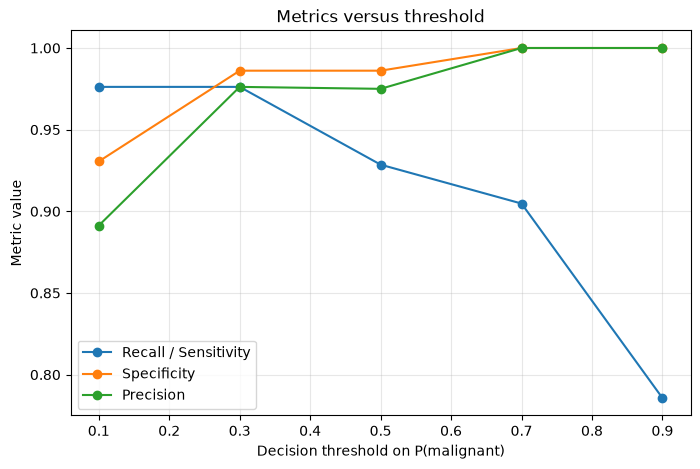

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(metric_results_df["Threshold"], metric_results_df["Recall"], marker="o", label="Recall / Sensitivity")
plt.plot(metric_results_df["Threshold"], metric_results_df["Specificity"], marker="o", label="Specificity")
plt.plot(metric_results_df["Threshold"], metric_results_df["Precision"], marker="o", label="Precision")
plt.xlabel("Decision threshold on P(malignant)")
plt.ylabel("Metric value")
plt.title("Metrics versus threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Reading it:** raising the threshold makes the model label fewer cases malignant, so FP falls (specificity and precision go up) but FN rises (recall goes down). For cancer screening a missed malignant case (FN) is the costly error, so we usually prefer a **lower** threshold and accept more false alarms.

## 8. ROC curve and precision-recall curve

* **ROC**: TPR $=TP/(TP+FN)$ against FPR $=FP/(FP+TN)$ over all thresholds. AUC = probability that a random positive gets a higher score than a random negative.
* **Precision-recall**: precision against recall over all thresholds. The no-skill baseline is the horizontal line at the prevalence $P(\text{malignant})$.

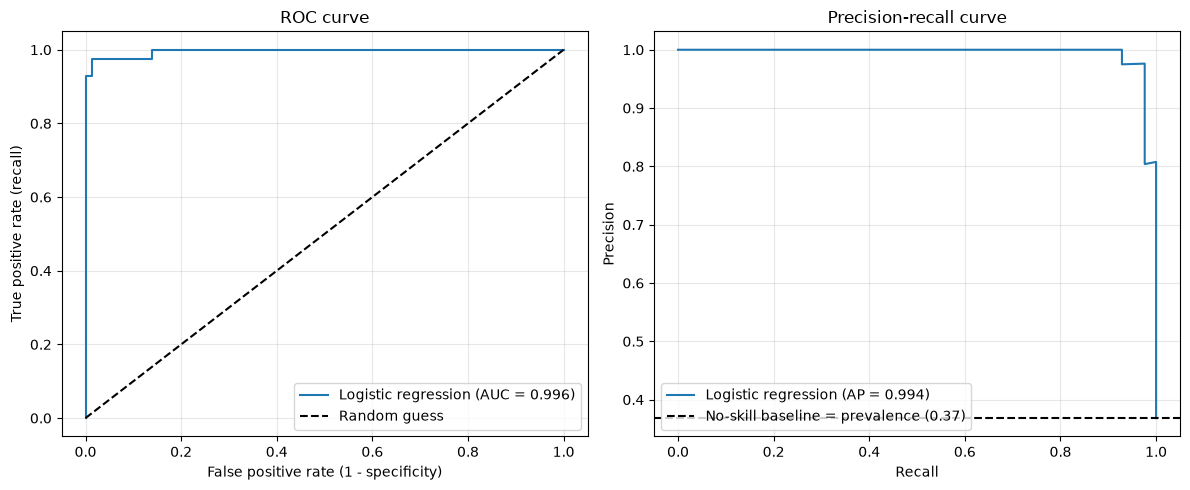

In [18]:
fpr, tpr, roc_thr = roc_curve(y_test, p_malignant)
prec, rec, pr_thr = precision_recall_curve(y_test, p_malignant)
auc_roc = roc_auc_score(y_test, p_malignant)
ap = average_precision_score(y_test, p_malignant)
prevalence = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"Logistic regression (AUC = {auc_roc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False positive rate (1 - specificity)")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec, label=f"Logistic regression (AP = {ap:.3f})")
axes[1].axhline(prevalence, color="k", linestyle="--", label=f"No-skill baseline = prevalence ({prevalence:.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()